# Lab 5 — Phần 3: Hai nguồn nói / FastICA (4.6–4.8)

**Một mic mono không đủ cho ICA 2×2.** Stereo cũng không đủ nếu hai kênh chỉ là bản sao. Ở đây lấy hai mic array thật, đồng bộ **23,28 giây AMI EN2009d**, cùng nội dung phần 2. Hai headset chỉ để đối chiếu gần đúng.

Hai thí nghiệm: **(a) thu thực tế** — không có clean ground truth; **(b) trộn có kiểm soát** hai đoạn solo từ chính hội thoại — có nguồn gốc để chấm điểm đúng đề. Không đánh đồng hai kết quả.

In [1]:
from pathlib import Path
import sys, os
ROOT = Path.cwd().resolve()
if not (ROOT/'src').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0,str(ROOT))
os.environ.setdefault('MPLCONFIGDIR',str(ROOT/'.cache/matplotlib'))
import matplotlib.pyplot as plt
from IPython.display import Audio, Markdown, display
from src.separation_experiments import run_real_separation, run_controlled_separation
from src.separation_visualization import (plot_ica_pipeline, plot_separation_spectrograms,
    plot_correlation_matching, plot_controlled_summary, listening_audio)
DATA = ROOT/'data/separation/ami23s'
RESULTS = ROOT/'results/separation'
FIGURES = ROOT/'results/figures/separation'
FIGURES.mkdir(parents=True,exist_ok=True)
CONFIG = dict(noise_snr_db=20., random_state=0, demo_case='well_clean', real_view=None)
# real_view=None xem cả 23s; có thể đổi thành (9.0,12.2) để phóng vùng overlap dài nhất.

### 1. Pipeline và chạy trên microphone thật

$X=AS$, FastICA tìm $\hat S=WX$ bằng tính độc lập/phi-Gaussian. Thuật toán chỉ nhận **hai quan sát X**, không nhận A, headset, nhãn người nói hay lịch overlap. Headset chỉ được dùng **sau fit** để ghép thứ tự/đảo dấu khi đánh giá; không sửa gain/delay để ép khớp.

- Đầu vào thật: **Array1-01 và Array1-05**, cùng khoảng gốc 4941,96–4965,24 giây.
- Headset-0/1 là mic gần người A/B nhưng vẫn có âm phòng/crosstalk, không phải clean tuyệt đối.
- Room echo và khác biệt đường truyền làm mô hình thực tế có chập, khác mô hình tức thời của ICA này.

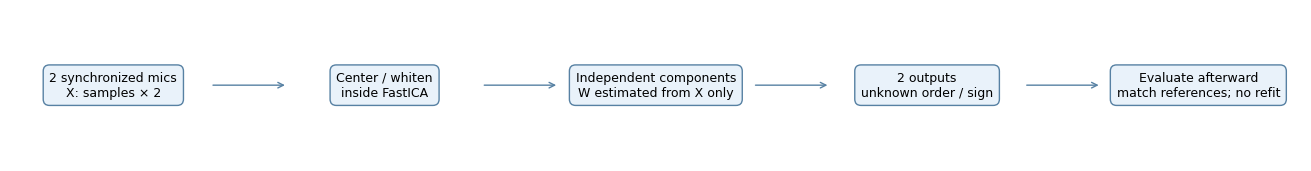

2 mic thật × 23.28s; correlation giữa hai mic = 0.560.
FastICA converged = True; 30 iterations. Hội tụ không đồng nghĩa tách đúng.


In [2]:
fig = plot_ica_pipeline()
fig.savefig(FIGURES/'pipeline.png',dpi=150)
plt.show()
real = run_real_separation(DATA,RESULTS)
r = real['summary']
print(f"2 mic thật × {r['duration_s']:.2f}s; correlation giữa hai mic = {r['input_correlation']:.3f}.")
print(f"FastICA converged = {r['converged']}; {r['iterations']} iterations. Hội tụ không đồng nghĩa tách đúng.")

### 2. Output của hội thoại thật 23 giây

Spectrogram dùng chung thang màu, **chuẩn hóa RMS chỉ để hiển thị/nghe** vì ICA không xác định biên độ tuyệt đối. Viền cyan đánh dấu vùng overlap theo annotation, không dùng để chạy ICA.

Ma trận dưới là tương quan zero-lag với **reference headset gần đúng**, nhạy với delay/âm phòng; không gọi là SNR hay accuracy. Xem thêm correlation của RMS envelope 20 ms và nghe so sánh. Audio stereo L/R chứa hai kênh tương ứng.

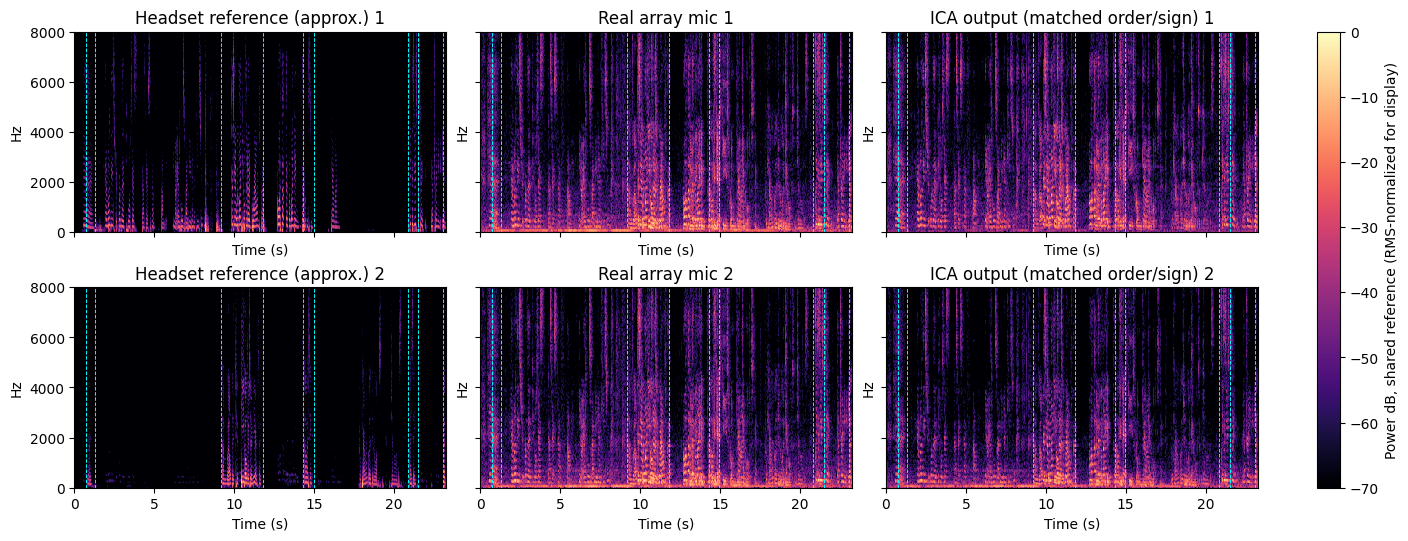

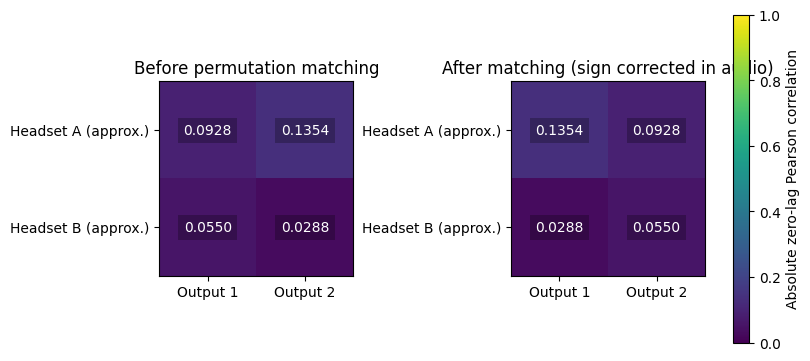

Hai microphone thật (L/R)


Headset tham chiếu gần đúng (L/R)


ICA output 1


ICA output 2


**|corr| waveform sau matching: 0.135 / 0.055.** RMS-envelope correlation: 0.588 / 0.353. Các chỉ số này chưa chứng minh hai output là hai người nói sạch; không kết luận thành công chỉ vì ICA hội tụ.

In [3]:
fig = plot_separation_spectrograms(real,time_range=CONFIG['real_view'])
fig.savefig(FIGURES/'real_23s_spectrogram.png',dpi=150)
plt.show()
fig = plot_correlation_matching(real)
fig.savefig(FIGURES/'real_23s_correlation.png',dpi=150)
plt.show()
for label,x in [('Hai microphone thật (L/R)',real['mixtures']),
                ('Headset tham chiếu gần đúng (L/R)',real['references']),
                ('ICA output 1',real['estimates'][:,0]),('ICA output 2',real['estimates'][:,1])]:
    print(label)
    display(Audio(listening_audio(x),rate=real['sr'],normalize=False))
display(Markdown(
    f"**|corr| waveform sau matching: {real['after'][0,0]:.3f} / {real['after'][1,1]:.3f}.** "
    f"RMS-envelope correlation: {r['rms_envelope_correlations'][0]:.3f} / {r['rms_envelope_correlations'][1]:.3f}. "
    'Các chỉ số này chưa chứng minh hai output là hai người nói sạch; không kết luận thành công chỉ vì ICA hội tụ.'))

### 3. Kiểm chứng đúng mô hình lab: nguồn từ cùng đoạn 23 giây

Cắt hai đoạn **solo 3 giây** khác thời điểm: người A ở 1,304–4,304s và B ở 17,768–20,768s trong preview. Chuẩn hóa RMS rồi chồng lên nhau bằng A. Đây là **mixture mô phỏng**, không phải overlap gốc của đoạn hội thoại.

$$A_{well}=\begin{bmatrix}1&0.6\\0.4&1\end{bmatrix},\quad
A_{near}=\begin{bmatrix}1&0.98\\0.98&1\end{bmatrix}$$

Chạy cả hai ma trận với/không noise trắng 20 dB. ICA chỉ thấy mixture; A và nguồn gốc chỉ dùng tạo dữ liệu/chấm điểm. Ghép output với source bằng tổng |correlation| lớn nhất, một-một; đảo dấu nếu cần. Không khớp lại bằng A⁻¹.

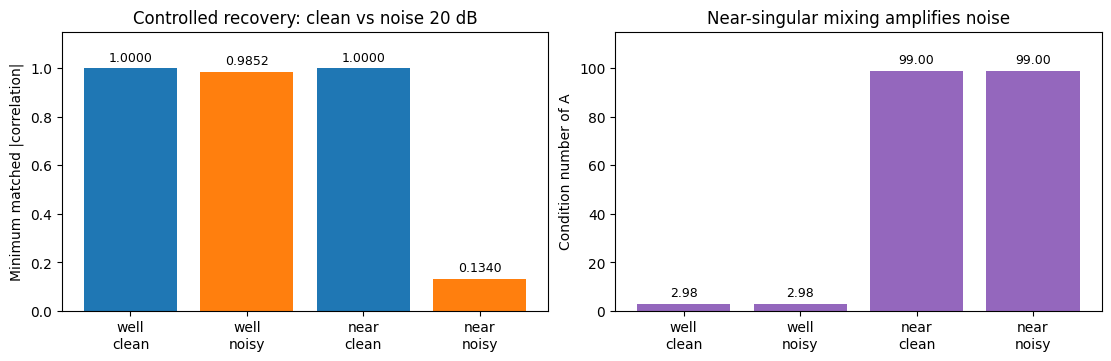

well_clean: det(A)=0.7600; cond(A)=2.98; min matched |corr|=1.0000; converged=True
well_noisy: det(A)=0.7600; cond(A)=2.98; min matched |corr|=0.9852; converged=True
near_clean: det(A)=0.0396; cond(A)=99.00; min matched |corr|=1.0000; converged=True
near_noisy: det(A)=0.0396; cond(A)=99.00; min matched |corr|=0.1340; converged=True


In [4]:
cases, metrics = run_controlled_separation(DATA,RESULTS,
    noise_snr_db=CONFIG['noise_snr_db'],random_state=CONFIG['random_state'])
fig = plot_controlled_summary(metrics)
fig.savefig(FIGURES/'controlled_summary.png',dpi=150)
plt.show()
for row in metrics.itertuples():
    print(f"{row.case}: det(A)={row.determinant:.4f}; cond(A)={row.condition:.2f}; "
          f"min matched |corr|={row.min_abs_correlation:.4f}; converged={row.converged}")

### 4. Ground truth / mixture / separated ở case được chọn

Đổi `demo_case`: `well_clean`, `well_noisy`, `near_clean`, `near_noisy`. Ma trận hiển thị **trước/sau ghép permutation** với nguồn thật của thí nghiệm mô phỏng. Audio L/R là nguồn A/B hoặc microphone 1/2 tương ứng.

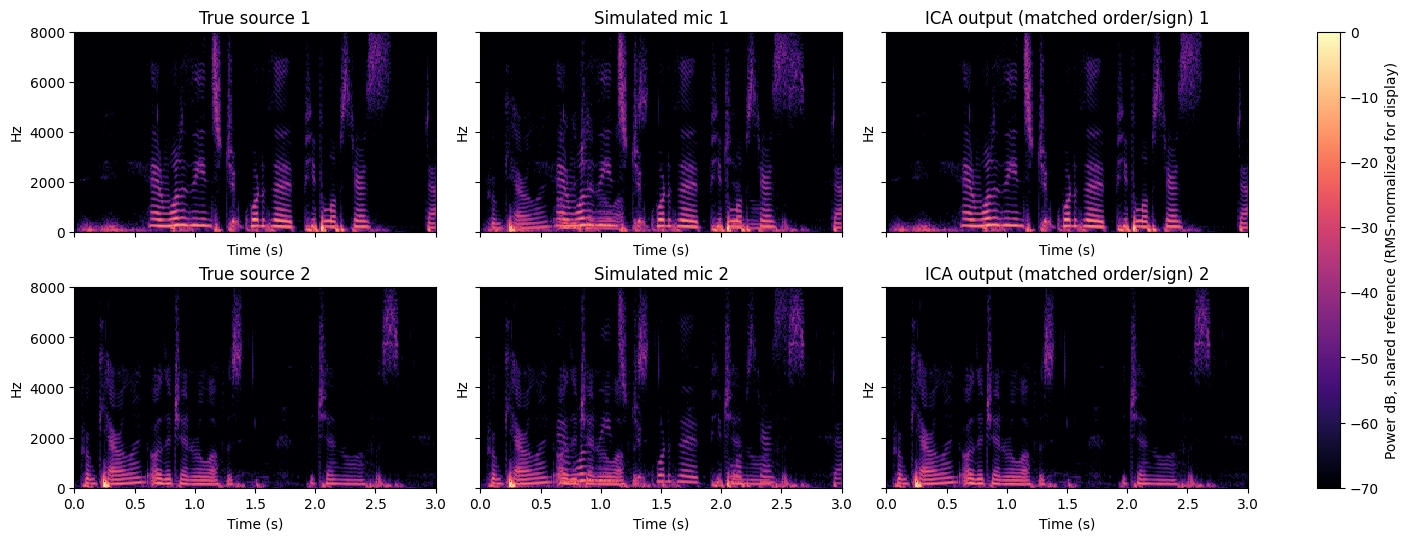

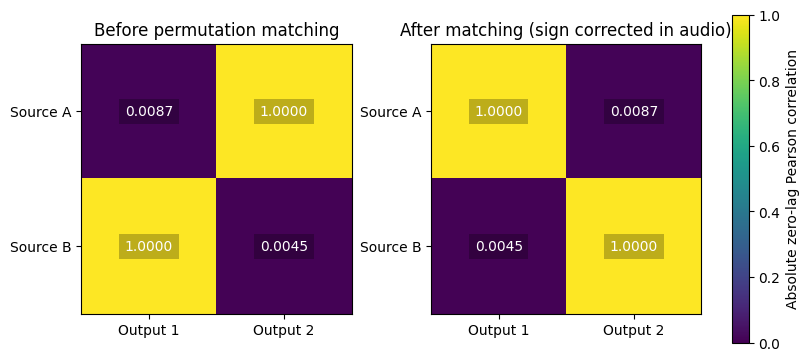

Nguồn gốc A/B (L/R)


Mixture 1/2 (L/R)


Nguồn tách A/B, matched (L/R)


**Kết quả kiểm chứng:** well_clean min |corr| **0.99996**; near_noisy min |corr| **0.134**. A gần suy biến vẫn tách được khi không nhiễu, nhưng nhạy nhiễu mạnh. Kết quả tốt của mô hình trộn tức thời không bảo đảm tách được phòng họp thật.

WAV, ma trận correlation, config và metrics: results/separation/.


In [5]:
demo = cases[CONFIG['demo_case']]
fig = plot_separation_spectrograms(demo)
fig.savefig(FIGURES/f"{CONFIG['demo_case']}_spectrogram.png",dpi=150)
plt.show()
fig = plot_correlation_matching(demo)
fig.savefig(FIGURES/f"{CONFIG['demo_case']}_correlation.png",dpi=150)
plt.show()
for label,x in [('Nguồn gốc A/B (L/R)',demo['references']),('Mixture 1/2 (L/R)',demo['mixtures']),
                ('Nguồn tách A/B, matched (L/R)',demo['estimates'])]:
    print(label)
    display(Audio(listening_audio(x),rate=demo['sr'],normalize=False))
clean_min = metrics[metrics.case=='well_clean'].min_abs_correlation.iloc[0]
near_noisy = metrics[metrics.case=='near_noisy'].min_abs_correlation.iloc[0]
display(Markdown(
    f"**Kết quả kiểm chứng:** well_clean min |corr| **{clean_min:.5f}**; "
    f"near_noisy min |corr| **{near_noisy:.3f}**. "
    'A gần suy biến vẫn tách được khi không nhiễu, nhưng nhạy nhiễu mạnh. '
    'Kết quả tốt của mô hình trộn tức thời không bảo đảm tách được phòng họp thật.'))
print('WAV, ma trận correlation, config và metrics: results/separation/.')